# Exploratory Data Analysis (EDA): Hotel Booking Demand

**HotelGuard** · Kelompok 3 · Perdagangan Elektronik dan Intelligent Bisnis
Disusun oleh: **Riyana**

Notebook ini mengeksplorasi data `hotel_bookings.csv` (data mentah, sebelum preprocessing) untuk memahami:
1. Karakteristik data: ukuran, tipe kolom, nilai kosong, duplikat
2. Distribusi target `is_canceled` (seimbang atau tidak)
3. Fitur apa saja yang berhubungan dengan pembatalan

Hasil EDA ini menjadi dasar pemilihan fitur dan langkah preprocessing di notebook `HotelGuard_Modeling_Manual.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

UNGU, PINK, ABU = '#6B4EE6', '#E85D9C', '#D9D4F0'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})

df = pd.read_csv('../backend/data/hotel_bookings.csv')
print('Jumlah baris :', f'{len(df):,}'.replace(',', '.'))
print('Jumlah kolom :', df.shape[1])
df.head()

Jumlah baris : 119.390
Jumlah kolom : 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Karakteristik data

Tipe data tiap kolom, jumlah nilai unik, dan contoh nilainya.

In [2]:
info = pd.DataFrame({
    'tipe': df.dtypes.astype(str),
    'nilai_unik': df.nunique(),
    'kosong': df.isna().sum(),
    'contoh': df.iloc[0]
})
info

,tipe,nilai_unik,kosong,contoh
hotel,str,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,479,0,342
arrival_date_year,int64,3,0,2015
arrival_date_month,str,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,35,0,0
adults,int64,14,0,2


In [3]:
numerik = df.select_dtypes('number').columns
kategorik = [c for c in df.columns if c not in numerik]
print(f'Kolom numerik  : {len(numerik)}')
print(f'Kolom kategorik: {len(kategorik)} ->', list(kategorik))
df[numerik].describe().T.round(2)

Kolom numerik  : 20
Kolom kategorik: 12 -> ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


**Catatan:**
- Data berupa **tabel (terstruktur)** dengan campuran kolom numerik dan kategorik, cocok untuk model berbasis pohon (Random Forest, XGBoost).
- `adr` memiliki nilai negatif dan nilai ekstrem (maks 5.400), sehingga perlu dibersihkan.
- Kolom `reservation_status` dan `reservation_status_date` berisi informasi **setelah** kejadian (status Canceled/Check-Out), jadi harus dibuang agar tidak terjadi *data leakage*.

## 2. Nilai kosong dan duplikat

,jumlah_kosong,persen
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31


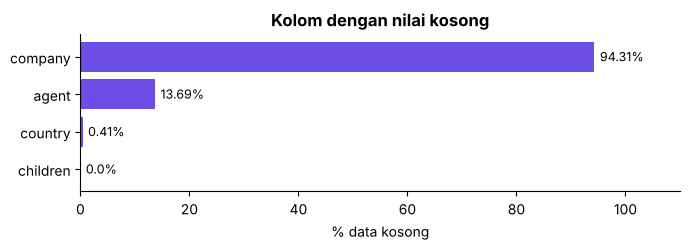

Baris duplikat: 31.994


In [4]:
kosong = df.isna().sum()
kosong = kosong[kosong > 0].sort_values()
persen = (kosong / len(df) * 100).round(2)
display(pd.DataFrame({'jumlah_kosong': kosong, 'persen': persen}))

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(persen.index, persen.values, color=UNGU)
for i, v in enumerate(persen.values):
    ax.text(v + 1, i, f'{v}%', va='center', fontsize=9)
ax.set_xlim(0, 110); ax.set_xlabel('% data kosong'); ax.set_title('Kolom dengan nilai kosong')
plt.tight_layout(); plt.show()

print('Baris duplikat:', f'{df.duplicated().sum():,}'.replace(',', '.'))

**Temuan:**
- `company` kosong sekitar 94%, sehingga tidak dipakai langsung, cukup diubah menjadi fitur biner *punya perusahaan / tidak*.
- `agent` kosong sekitar 14% (pemesanan tanpa agen), diisi kategori tersendiri.
- `country` dan `children` hanya sedikit yang kosong, sehingga baris tersebut bisa dihapus atau diisi.
- Terdapat sekitar 32 ribu baris duplikat yang dihapus pada tahap preprocessing.

## 3. Distribusi target `is_canceled`

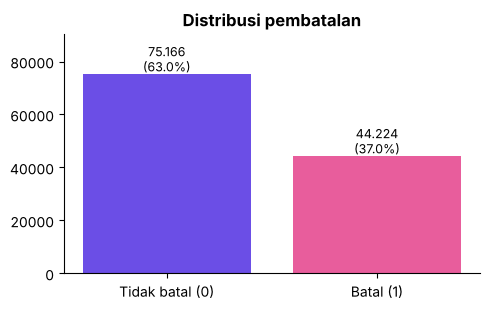

In [5]:
jml = df['is_canceled'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
bar = ax.bar(['Tidak batal (0)', 'Batal (1)'], jml.values, color=[UNGU, PINK])
for b, v in zip(bar, jml.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({v / len(df):.1%})'.replace(',', '.'), ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, jml.max() * 1.2); ax.set_title('Distribusi pembatalan')
plt.tight_layout(); plt.show()

Sekitar **37%** reservasi batal dan 63% tidak batal, sehingga data **tidak seimbang**. Karena itu evaluasi model tidak cukup memakai accuracy saja, tetapi juga **precision, recall, F1-score, dan confusion matrix**, serta memakai pembagian data *stratified*.

In [6]:
def rasio_batal(kolom, urutan=None, top=None):
    g = df.groupby(kolom)['is_canceled'].agg(['mean', 'size'])
    if top: g = g.sort_values('size', ascending=False).head(top)
    if urutan is not None: g = g.reindex(urutan)
    return g

def plot_batal(g, judul, ax, rotasi=0):
    warna = [PINK if v >= df['is_canceled'].mean() else UNGU for v in g['mean']]
    ax.bar(g.index.astype(str), g['mean'] * 100, color=warna)
    ax.axhline(df['is_canceled'].mean() * 100, color='gray', ls='--', lw=1)
    ax.set_ylabel('% batal'); ax.set_title(judul)
    ax.tick_params(axis='x', rotation=rotasi)

## 4. Pembatalan berdasarkan tipe hotel dan tipe deposit

Garis putus-putus = rata-rata pembatalan seluruh data. Batang pink = di atas rata-rata.

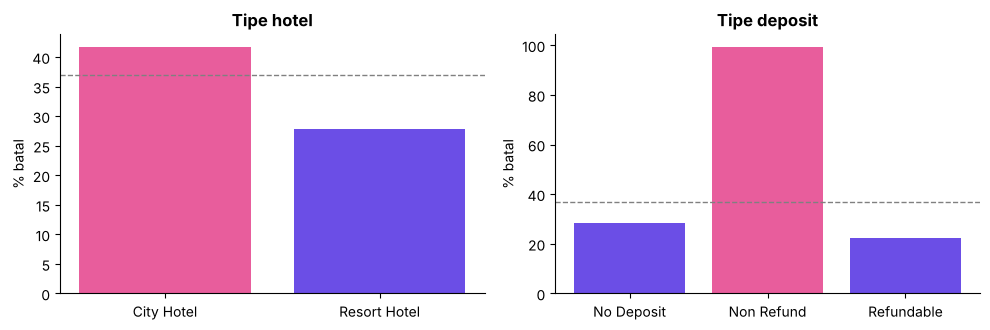

,mean,size
deposit_type,,
No Deposit,0.284,104641
Non Refund,0.994,14587
Refundable,0.222,162


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
plot_batal(rasio_batal('hotel'), 'Tipe hotel', ax[0])
plot_batal(rasio_batal('deposit_type'), 'Tipe deposit', ax[1])
plt.tight_layout(); plt.show()
display(rasio_batal('deposit_type').round(3))

- **City Hotel** lebih sering batal (~42%) dibanding Resort Hotel (~28%).
- **Non Refund** hampir selalu batal (~99%). Pola ini tidak wajar secara bisnis (kemungkinan pemesanan massal oleh agen yang lalu dibatalkan), tetapi menjadi sinyal yang sangat kuat bagi model.

## 5. Pembatalan berdasarkan lead time

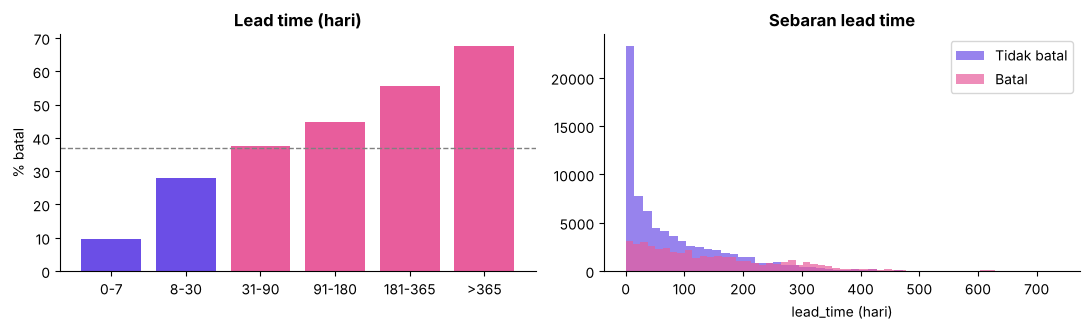

In [8]:
kelompok = pd.cut(df['lead_time'], [-1, 7, 30, 90, 180, 365, 800],
                  labels=['0-7', '8-30', '31-90', '91-180', '181-365', '>365'])
g = df.groupby(kelompok, observed=True)['is_canceled'].agg(['mean', 'size'])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
plot_batal(g, 'Lead time (hari)', ax[0])
ax[1].hist(df.loc[df.is_canceled == 0, 'lead_time'], bins=50, alpha=.7, color=UNGU, label='Tidak batal')
ax[1].hist(df.loc[df.is_canceled == 1, 'lead_time'], bins=50, alpha=.7, color=PINK, label='Batal')
ax[1].set_xlabel('lead_time (hari)'); ax[1].set_title('Sebaran lead time'); ax[1].legend()
plt.tight_layout(); plt.show()

Semakin jauh jarak pemesanan dengan kedatangan, semakin besar peluang batal: **~10%** untuk lead time di bawah 1 minggu, naik hingga **~68%** untuk lebih dari 1 tahun. `lead_time` adalah fitur numerik dengan korelasi tertinggi terhadap pembatalan.

## 6. Pola musiman (bulan kedatangan)

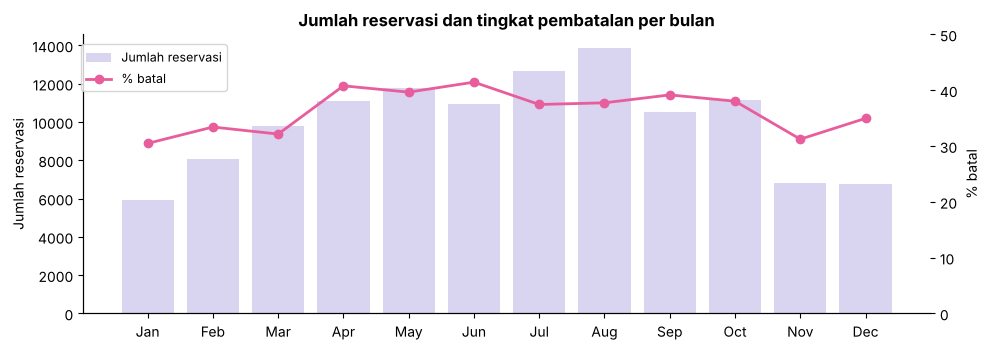

In [9]:
BULAN = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
         'August', 'September', 'October', 'November', 'December']
g = rasio_batal('arrival_date_month', urutan=BULAN)
g.index = [b[:3] for b in BULAN]

fig, ax1 = plt.subplots(figsize=(10, 3.6))
ax1.bar(g.index, g['size'], color=ABU, label='Jumlah reservasi')
ax1.set_ylabel('Jumlah reservasi')
ax2 = ax1.twinx()
ax2.plot(g.index, g['mean'] * 100, color=PINK, marker='o', lw=2, label='% batal')
ax2.set_ylabel('% batal'); ax2.set_ylim(0, 50)
ax1.set_title('Jumlah reservasi dan tingkat pembatalan per bulan')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.88), fontsize=9)
plt.tight_layout(); plt.show()

Reservasi paling ramai pada **Juli-Agustus** (musim panas Eropa). Tingkat pembatalan tertinggi pada **April-Juni** (~40-42%) dan terendah pada **Januari** dan **November** (~31%).

## 7. Segmen pasar, tipe pelanggan, dan negara

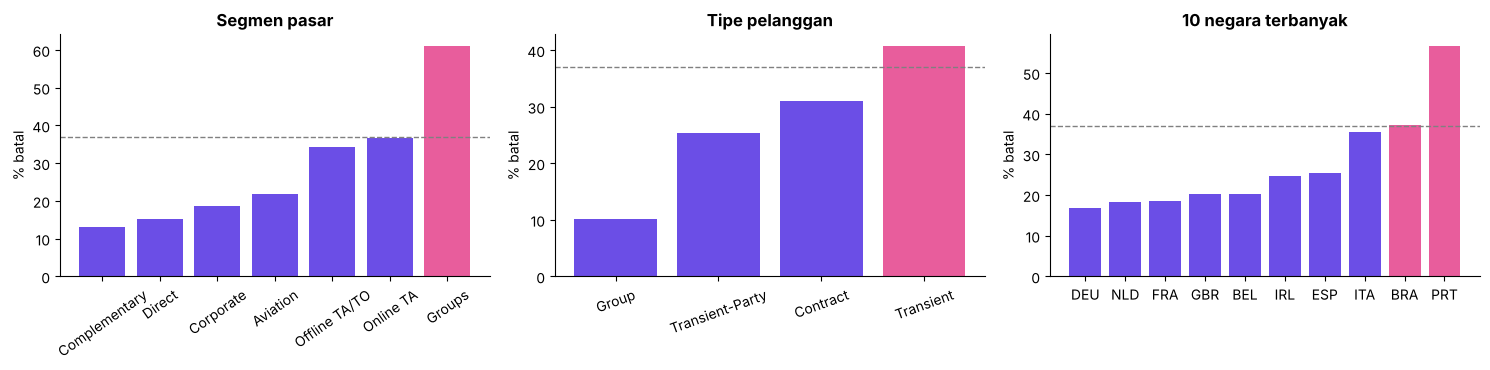

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
seg = rasio_batal('market_segment').drop('Undefined', errors='ignore').sort_values('mean')
plot_batal(seg, 'Segmen pasar', ax[0], rotasi=35)
plot_batal(rasio_batal('customer_type').sort_values('mean'), 'Tipe pelanggan', ax[1], rotasi=20)
plot_batal(rasio_batal('country', top=10).sort_values('mean'), '10 negara terbanyak', ax[2], rotasi=0)
plt.tight_layout(); plt.show()

- Segmen **Groups** (~61%) dan **Online TA** (~37%) paling sering batal; **Direct** dan **Corporate** paling jarang.
- Pelanggan **Transient** (perorangan) lebih sering batal dibanding Group atau Contract.
- Tamu dari **Portugal (PRT)**, negara lokasi hotel, membatalkan ~57%, jauh di atas negara lain (~17-37%). Karena negara sangat banyak, pada preprocessing hanya 15 negara teratas yang dipertahankan, sisanya digabung menjadi *Lainnya*.

## 8. Permintaan khusus dan tempat parkir

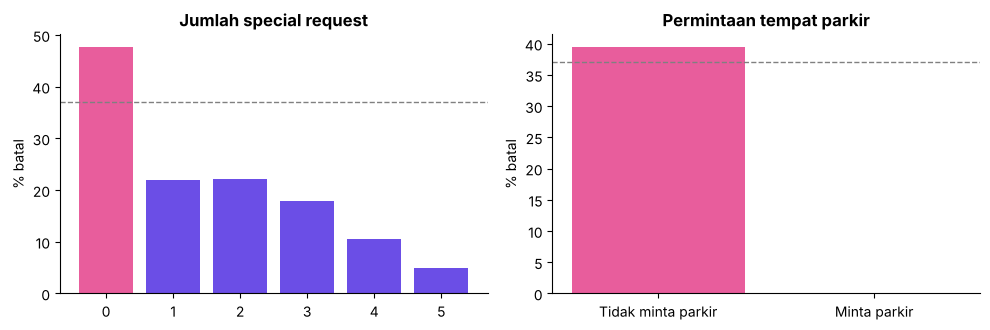

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
plot_batal(rasio_batal('total_of_special_requests'), 'Jumlah special request', ax[0])
parkir = df.groupby(df['required_car_parking_spaces'] > 0)['is_canceled'].agg(['mean', 'size'])
parkir.index = ['Tidak minta parkir', 'Minta parkir']
plot_batal(parkir, 'Permintaan tempat parkir', ax[1])
plt.tight_layout(); plt.show()

Tamu yang punya **special request** atau **meminta tempat parkir** jauh lebih jarang batal. Tamu yang meminta parkir bahkan **0% batal**. Ini menandakan tamu tersebut benar-benar berniat datang.

## 9. Harga kamar (ADR)

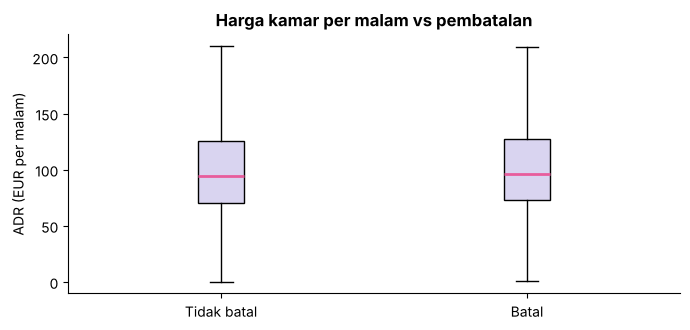

Median ADR tidak batal: 94.5
Median ADR batal      : 96.3


In [12]:
adr = df[(df['adr'] > 0) & (df['adr'] < 400)]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.boxplot([adr.loc[adr.is_canceled == 0, 'adr'], adr.loc[adr.is_canceled == 1, 'adr']],
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor=ABU), medianprops=dict(color=PINK, lw=2))
ax.set_xticks([1, 2], ['Tidak batal', 'Batal'])
ax.set_ylabel('ADR (EUR per malam)'); ax.set_title('Harga kamar per malam vs pembatalan')
plt.tight_layout(); plt.show()
print('Median ADR tidak batal:', adr.loc[adr.is_canceled == 0, 'adr'].median())
print('Median ADR batal      :', adr.loc[adr.is_canceled == 1, 'adr'].median())

Median harga reservasi yang batal sedikit lebih tinggi, tetapi perbedaannya kecil. ADR berpengaruh lemah jika berdiri sendiri, dan lebih berguna bila dikombinasikan dengan fitur lain (hal yang ditangani model pohon).

## 10. Korelasi fitur numerik dengan pembatalan

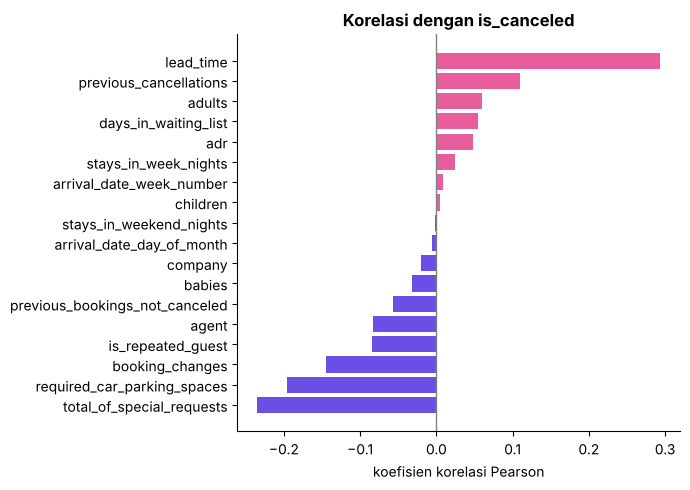

In [13]:
kor = df.select_dtypes('number').corr()['is_canceled'].drop(['is_canceled', 'arrival_date_year'])
kor = kor.sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(kor.index, kor.values, color=[PINK if v > 0 else UNGU for v in kor.values])
ax.axvline(0, color='gray', lw=1)
ax.set_title('Korelasi dengan is_canceled'); ax.set_xlabel('koefisien korelasi Pearson')
plt.tight_layout(); plt.show()

- Korelasi positif terbesar: **lead_time** dan **previous_cancellations** (makin besar, makin berisiko batal).
- Korelasi negatif terbesar: **total_of_special_requests**, **required_car_parking_spaces**, dan **booking_changes**.
- Nilai korelasi tergolong kecil (< 0,3) karena hubungan fitur dengan pembatalan **tidak linear**. Ini salah satu alasan memilih model berbasis pohon (Random Forest dan XGBoost) dibanding model linear.

## 11. Kesimpulan EDA

| Temuan | Tindak lanjut di preprocessing / modeling |
|---|---|
| Data 119.390 baris, 32 kolom, campuran numerik dan kategorik | Model berbasis pohon; kategorik diubah dengan One-Hot Encoding |
| ~32 ribu duplikat, `company` 94% kosong, `agent` 14% kosong | Hapus duplikat; `company` jadi fitur biner; `agent` kosong jadi kategori sendiri |
| `reservation_status` berisi hasil akhir | Dibuang untuk mencegah data leakage |
| ADR negatif dan ekstrem | Baris tidak wajar dibersihkan |
| Target tidak seimbang (37% batal) | Pembagian stratified; metrik F1, precision, recall, confusion matrix; bobot kelas |
| Negara dan agen sangat banyak | Ambil 15 teratas, sisanya *Lainnya* |
| Fitur kuat: deposit, lead time, segmen, negara, special request, parkir | Menjadi input utama halaman Prediksi |
| Hubungan fitur dengan target tidak linear | Random Forest dan XGBoost |